In [109]:
import pandas as pd
import numpy as np
import yfinance as yf
from functools import reduce
import datetime as dt

In [256]:
df_close = pd.read_excel('account_52157453_pl_xlsx_2005-12-31_2026-06-02.xlsx', sheet_name=0, header=12).iloc[:-1,[1,2,3,4,5,6,7,8,19]]

In [251]:
pd.read_excel('account_52157453_pl_xlsx_2005-12-31_2026-06-02.xlsx', sheet_name=0, header=12)

,Unnamed: 0,Position,Symbol,Type,Volume,Open time,Open price,Close time,Close price,Open origin,...,Purchase value,Sale value,SL,TP,Margin,Commission,Swap,Rollover,Gross P/L,Comment
0,NaN,1944346732,US500,BUY,0.020,2025-07-29 09:14:18.473,6431.70,2025-08-01 15:45:26.038,6267.40,xStation Mobile iOS,...,NaN,NaN,NaN,NaN,1190.27,0,-16.49,0.0,-606.45,[S/O 49.96% 723.59 / 1448.33 (PLN)]
1,NaN,1974374314,US100,SELL,0.005,2025-08-14 16:47:45.114,24000.55,2025-08-25 12:01:50.062,23504.04,xStation Mobile iOS,...,NaN,NaN,NaN,NaN,438.26,0,0.00,0.0,181.06,NaN
2,NaN,1952943649,US100,BUY,0.005,2025-08-01 17:52:40.961,22982.24,2025-08-25 12:01:54.922,23502.21,xStation Mobile iOS,...,NaN,NaN,NaN,NaN,424.43,0,-49.64,0.0,189.62,NaN
3,NaN,1944352898,DE40,BUY,0.002,2025-07-29 09:16:44.788,24196.30,2025-10-02 15:56:34.542,24594.30,xStation Mobile iOS,...,NaN,NaN,NaN,NaN,258.06,0,-55.50,-29.4,84.68,NaN
4,NaN,Total,NaN,NaN,NaN,NaT,NaN,NaT,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0,-121.63,-29.4,-151.09,NaN


In [254]:
df_open = pd.read_excel('account_52157453_pl_xlsx_2005-12-31_2026-06-02.xlsx', sheet_name=1, header=10).iloc[:-1,[1,2,3,4,5,6,7,8,15]]

In [268]:
pd.read_excel('account_52157453_pl_xlsx_2005-12-31_2026-06-02.xlsx', sheet_name=0, header=12).iloc[:-1,[1,2,3,4,5,6,7,8,19]]

,Position,Symbol,Type,Volume,Open time,Open price,Close time,Close price,Gross P/L
0,1944346732,US500,BUY,0.020,2025-07-29 09:14:18.473,6431.70,2025-08-01 15:45:26.038,6267.40,-606.45
1,1974374314,US100,SELL,0.005,2025-08-14 16:47:45.114,24000.55,2025-08-25 12:01:50.062,23504.04,181.06
2,1952943649,US100,BUY,0.005,2025-08-01 17:52:40.961,22982.24,2025-08-25 12:01:54.922,23502.21,189.62
3,1944352898,DE40,BUY,0.002,2025-07-29 09:16:44.788,24196.30,2025-10-02 15:56:34.542,24594.30,84.68


In [264]:
pd.read_excel('account_52157453_pl_xlsx_2005-12-31_2026-06-02.xlsx', sheet_name=1, header=10).iloc[:-1,[1,2,3,4,5,6,7,8,15]]

,Position,Symbol,Type,Volume,Open time,Open price,Market price,Purchase value,Gross P/L
0,2001655284,IS3S.DE,BUY,0.5114,2025-09-02 11:10:24.608,45.120,69.24,98.98,50.21
1,2326685385,IS3S.DE,BUY,0.6593,2026-01-27 10:20:55.187,53.270,69.24,148.48,43.86
2,2146116938,ZPRR.DE,BUY,1.1221,2025-11-05 09:04:12.684,61.324,72.67,294.48,49.09
3,2001655291,QDV5.DE,BUY,2.8556,2025-09-02 11:10:24.642,8.082,7.26,99.00,-11.65
4,2326685388,IUSN.DE,BUY,4.2982,2026-01-27 10:20:55.196,8.172,8.86,148.50,11.95
...,...,...,...,...,...,...,...,...,...
62,2146091673,XTB.PL,BUY,10.0000,2025-11-05 09:00:00.714,70.760,102.74,707.60,319.80
63,2362710276,CDR.PL,BUY,2.0333,2026-02-09 09:55:27.682,245.900,226.50,499.99,-39.45
64,2002359896,SPOT.US,BUY,0.1988,2025-09-02 15:30:07.994,669.000,507.05,489.55,-125.00
65,2596113661,CDR.PL,BUY,0.8347,2026-05-27 13:30:18.303,239.500,226.50,199.91,-10.85


In [52]:
with pd.ExcelWriter('XTB.xlsx', engine='openpyxl', mode='a', if_sheet_exists='replace') as writer:  
    df_close.to_excel(writer, sheet_name='Close_positions', index=False)

In [249]:
pd.concat([df_open, df_close])

,Position,Symbol,Type,Volume,Open time,Open price,Market price,Purchase value,Gross P/L,Close time,Close price,Margin,Swap
0,2001655284,IS3S.DE,BUY,0.5114,2025-09-02 11:10:24.608,45.120,69.24,98.98,50.21,NaT,NaN,NaN,NaN
1,2326685385,IS3S.DE,BUY,0.6593,2026-01-27 10:20:55.187,53.270,69.24,148.48,43.86,NaT,NaN,NaN,NaN
2,2146116938,ZPRR.DE,BUY,1.1221,2025-11-05 09:04:12.684,61.324,72.67,294.48,49.09,NaT,NaN,NaN,NaN
3,2001655291,QDV5.DE,BUY,2.8556,2025-09-02 11:10:24.642,8.082,7.26,99.00,-11.65,NaT,NaN,NaN,NaN
4,2326685388,IUSN.DE,BUY,4.2982,2026-01-27 10:20:55.196,8.172,8.86,148.50,11.95,NaT,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,1944292432,ETFBS80TR.PL,BUY,3.2855,2025-07-29 09:08:29.937,456.450,502.70,1499.67,151.95,NaT,NaN,NaN,NaN
0,1944346732,US500,BUY,0.0200,2025-07-29 09:14:18.473,6431.700,NaN,NaN,-606.45,2025-08-01 15:45:26.038,6267.40,1190.27,-16.49
1,1974374314,US100,SELL,0.0050,2025-08-14 16:47:45.114,24000.550,NaN,NaN,181.06,2025-08-25 12:01:50.062,23504.04,438.26,0.00
2,1952943649,US100,BUY,0.0050,2025-08-01 17:52:40.961,22982.240,NaN,NaN,189.62,2025-08-25 12:01:54.922,23502.21,424.43,-49.64


In [258]:
df_open['Latest time'] = dt.datetime.now().strftime('%Y-%m-%d')

In [ ]:

for sheet in range(0,2):
    

In [259]:
df_open

,Position,Symbol,Type,Volume,Open time,Open price,Market price,Purchase value,Gross P/L,Latest time
0,2001655284,IS3S.DE,BUY,0.5114,2025-09-02 11:10:24.608,45.120,69.24,98.98,50.21,2026-06-16
1,2326685385,IS3S.DE,BUY,0.6593,2026-01-27 10:20:55.187,53.270,69.24,148.48,43.86,2026-06-16
2,2146116938,ZPRR.DE,BUY,1.1221,2025-11-05 09:04:12.684,61.324,72.67,294.48,49.09,2026-06-16
3,2001655291,QDV5.DE,BUY,2.8556,2025-09-02 11:10:24.642,8.082,7.26,99.00,-11.65,2026-06-16
4,2326685388,IUSN.DE,BUY,4.2982,2026-01-27 10:20:55.196,8.172,8.86,148.50,11.95,2026-06-16
...,...,...,...,...,...,...,...,...,...,...
62,2146091673,XTB.PL,BUY,10.0000,2025-11-05 09:00:00.714,70.760,102.74,707.60,319.80,2026-06-16
63,2362710276,CDR.PL,BUY,2.0333,2026-02-09 09:55:27.682,245.900,226.50,499.99,-39.45,2026-06-16
64,2002359896,SPOT.US,BUY,0.1988,2025-09-02 15:30:07.994,669.000,507.05,489.55,-125.00,2026-06-16
65,2596113661,CDR.PL,BUY,0.8347,2026-05-27 13:30:18.303,239.500,226.50,199.91,-10.85,2026-06-16


In [257]:
df_close

,Position,Symbol,Type,Volume,Open time,Open price,Close time,Close price,Gross P/L
0,1944346732,US500,BUY,0.020,2025-07-29 09:14:18.473,6431.70,2025-08-01 15:45:26.038,6267.40,-606.45
1,1974374314,US100,SELL,0.005,2025-08-14 16:47:45.114,24000.55,2025-08-25 12:01:50.062,23504.04,181.06
2,1952943649,US100,BUY,0.005,2025-08-01 17:52:40.961,22982.24,2025-08-25 12:01:54.922,23502.21,189.62
3,1944352898,DE40,BUY,0.002,2025-07-29 09:16:44.788,24196.30,2025-10-02 15:56:34.542,24594.30,84.68


In [64]:
# This function reads all open transactions and put them into a single table with information about
# Symbol, Volume, Open price, Portfolio allocation, Market price, Currency and Gross P/L

def open_stocks_data_and_present_open_position(path_to_excel):
    df_open = pd.read_excel(path_to_excel, sheet_name=1, header=10).iloc[:-1,[1,2,3,4,5,6,7,8,15]]
    total_invested = df_open['Purchase value'].sum()
    df_open['Portoflio Allocation'] = round(df_open['Purchase value']/total_invested,3)
    df_open_positions = df_open.groupby('Symbol').agg({'Volume': 'sum','Open price':'mean','Portoflio Allocation':'sum'}).reset_index()
    df_open_positions['Market price'] = 0
    df_open_positions['Currecny'] = 'Unknown'
    for index,ticker_ in enumerate(df_open_positions['Symbol']):
        a, b = ticker_.split('.')
        print(b)
        if b=='DE':
            df_open_positions['Currecny'][index] = 'EUR'
        elif b=='US':
            df_open_positions['Currecny'][index] = 'USD'
        elif b=='PL':
            df_open_positions['Currecny'][index] = 'PLN'
        b = b.replace('PL','WA')
        ticker_ = a + '.' + b
        try:
            ticker = yf.Ticker(ticker_)
            last_price = ticker.fast_info.last_price
        except:
            last_price = np.nan
        
        df_open_positions['Market price'][index] = last_price
    df_open_positions['Gross P/L'] = (df_open_positions['Market price'] - df_open_positions['Open price']) * df_open_positions['Volume']
    df_open_positions['Portoflio Allocation'] = df_open_positions['Portoflio Allocation'].map('{:.1%}'.format)
    return df_open_positions

In [65]:
df_ = open_stocks_data_and_present_open_position('account_52157453_pl_xlsx_2005-12-31_2026-06-02.xlsx')

DE


/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610112505.py:12: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_open_positions['Currecny'][index] = 'EUR'
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610

PL
PL


/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610112505.py:16: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_open_positions['Currecny'][index] = 'PLN'
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610

PL
DE


...

/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610112505.py:12: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_open_positions['Currecny'][index] = 'EUR'
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610

PL


/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610112505.py:16: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_open_positions['Currecny'][index] = 'PLN'
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610

DE


/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610112505.py:12: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_open_positions['Currecny'][index] = 'EUR'
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2610

In [228]:
df_

,Symbol,Volume,Open price,Portoflio Allocation,Market price,Currecny,Gross P/L
0,2B76.DE,28.8002,13.657417,0.122,18.486000,EUR,139.064167
1,CDR.PL,2.8680,242.700000,0.053,224.500000,PLN,-52.197600
2,ETFBM40TR.PL,7.0821,127.080000,0.068,158.000000,PLN,218.978532
3,ETFBS80TR.PL,3.2855,456.450000,0.113,493.700012,PLN,122.384915
4,IS3N.DE,5.4158,37.296167,0.061,48.955002,EUR,63.141919
5,IS3S.DE,4.0860,48.068833,0.061,70.150002,EUR,90.223653
6,IUSN.DE,25.9540,7.572167,0.061,9.107000,EUR,39.835073
7,QDV5.DE,23.8806,8.222383,0.061,7.513000,EUR,-16.940499
8,SPOT.US,0.1988,669.000000,0.037,NaN,USD,NaN
9,SXR8.DE,0.3311,605.316667,0.061,697.020020,EUR,30.362980


In [200]:
def open_stocks_data_portfolio(path_to_excel):
    df_open = pd.read_excel(path_to_excel, sheet_name=1, header=10).iloc[:-1,[1,2,3,4,5,6,7,8,15]]
    total_invested = df_open['Purchase value'].sum()
    df_open['Portoflio Allocation'] = round(df_open['Purchase value']/total_invested,3)
    ticker_names = []
    all_dfs = []
    todays_date = dt.datetime.now().strftime('%Y-%m-%d')
    for i in range(len(df_open)):
        trans_ = df_open.iloc[i,:]
        a, b = trans_['Symbol'].split('.')
        b = b.replace('PL','WA')
        if a == 'SPOT':
            trans_['Symbol'] = a
        else:
            trans_['Symbol'] = a + '.' + b
        ticker_names.append(trans_['Symbol'])
        trans_hist = yf.download(trans_['Symbol'], trans_['Open time'], todays_date)['Close']
        trans_hist = trans_hist * trans_['Volume']
        all_dfs.append(trans_hist)

    portfolio_df = pd.DataFrame()
    for ticker_ in list(set(ticker_names)):
        temp_df = pd.DataFrame()
        for i in all_dfs:
            if i.columns[0] == ticker_:
                #temp_df = pd.concat([temp_df, i], axis=1)
                temp_df = temp_df.add(i, fill_value=0)
        portfolio_df = pd.concat([portfolio_df, temp_df], axis=1)
    portfolio_df = portfolio_df.sort_index()

    for col in portfolio_df.columns:
        portfolio_df[col] = portfolio_df[col].ffill()

    portfolio_df['Portfolio'] = portfolio_df.sum(axis=1, numeric_only=False)
    
    return portfolio_df

In [201]:
df_df = open_stocks_data_portfolio('account_52157453_pl_xlsx_2005-12-31_2026-06-02.xlsx')

/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/1933989330.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trans_['Symbol'] = a + '.' + b
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/1933989330.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  trans_hist = yf.download(trans_['Symbol'], trans_['Open time'], todays_date)['Close']
[*********************100%***********************]  1 of 1 completed
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/1933989330.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trans_['Symbol'] = a +

<Axes: xlabel='Date'>

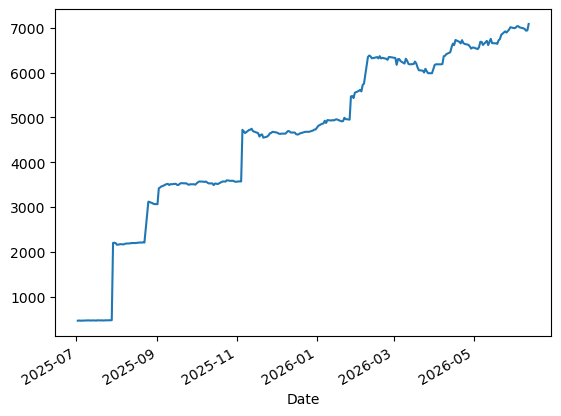

In [206]:
df_df['Portfolio'].plot()

In [215]:
df_df.tail(25)

Ticker,ETFBS80TR.WA,ETFBM40TR.WA,SXRT.DE,QDV5.DE,IUSN.DE,ZPRR.DE,XDWH.DE,XTB.WA,2B76.DE,V60D.DE,IS3N.DE,CDR.WA,SPOT,SXR8.DE,IS3S.DE,Portfolio
Date,,,,,,,,,,,,,,,,
2026-05-11,1586.403695,1039.510629,213.551823,175.188081,226.241018,231.576762,197.916837,1031.202011,505.040287,146.815374,255.690759,530.081335,83.396600,224.174565,263.710444,6710.500221
2026-05-12,1571.783180,1026.479591,210.465000,171.080619,222.841055,226.383007,200.526597,1016.762085,490.064225,145.923358,246.505547,519.508150,86.030700,222.995850,259.093259,6616.442224
2026-05-13,1575.725820,1034.269836,212.476104,172.919429,224.528055,229.174655,201.226762,1047.759705,496.803450,146.723883,253.470262,520.728142,85.662919,225.366517,264.731944,6691.567483
2026-05-14,1578.846985,1048.434036,215.001696,175.761219,226.630337,232.096150,203.030263,1061.814651,499.741050,147.981833,255.566182,527.234665,85.988954,228.856324,267.796444,6754.780789
2026-05-15,1575.890055,1044.609750,211.260096,175.164202,223.671573,227.778831,201.820866,1014.836731,488.681805,147.044090,248.568969,524.184715,86.863672,227.697474,262.688944,6660.761773
2026-05-18,1575.397250,1053.391593,212.569650,173.373161,222.555545,225.636418,201.099462,1007.905579,480.963362,146.266442,246.668035,534.554558,88.467990,225.810200,260.155613,6654.814857
2026-05-19,1576.218625,1050.983597,212.289027,172.513454,221.076163,223.136907,204.833747,1015.991974,476.528096,145.923358,243.792234,529.267965,87.788091,225.459235,259.215834,6645.018307
2026-05-20,1590.017765,1064.156307,216.919254,175.689571,223.905154,228.006057,204.197215,1032.549744,493.059448,146.861110,248.460651,522.964785,86.144017,227.220689,264.445925,6724.597693
2026-05-21,1597.902945,1070.530262,216.404796,174.065694,224.709732,230.083559,205.682450,1032.934799,493.635410,147.204193,248.915576,518.491500,97.398083,227.558418,265.835150,6751.352567


In [219]:
df_df['Portfolio'].diff(5)[-1]

/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/3653890141.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df_df['Portfolio'].diff(5)[-1]


np.float64(75.49157542886769)

In [220]:
df_df['Portfolio'].pct_change(5)[-1]

/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/1237142355.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df_df['Portfolio'].pct_change(5)[-1]


np.float64(0.010765263372210399)

In [221]:
df_df['Portfolio'].diff(5*4)[-1]

/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/2964708900.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df_df['Portfolio'].diff(5*4)[-1]


np.float64(427.24522496156715)

In [222]:
df_df['Portfolio'].pct_change(5*4)[-1]

/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_4408/1629230640.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df_df['Portfolio'].pct_change(5*4)[-1]


np.float64(0.06414359790976198)